# 01 - TOI catalog EDA

Questions: how are the labels distributed, do the two classes differ in catalog features, and is
anything so predictive that it could be a shortcut (leakage) instead of real signal?

Reminder: labels are catalog **dispositions** (CP/KP = 1, FP/FA = 0), not ground truth.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score

from transit_classifier.catalog import clean_toi_catalog, fetch_toi_catalog

POS, NEG = "#2a78d6", "#eb6834"   # blue = CP/KP, orange = FP/FA
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110})

df = clean_toi_catalog(fetch_toi_catalog())
lab = df[df.label.notna()].copy()
print(len(df), "foldable TOIs;", len(lab), "labeled")

8036 foldable TOIs; 2801 labeled


## 1. Label coverage

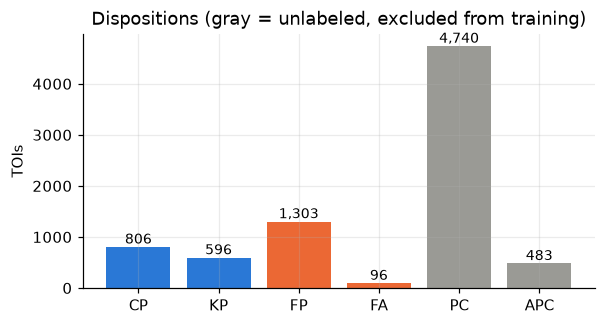

In [2]:
order = ["CP", "KP", "FP", "FA", "PC", "APC"]
counts = df.disposition.value_counts().reindex(order)
colors = [POS, POS, NEG, NEG, "#9a9a95", "#9a9a95"]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(counts.index, counts.values, color=colors)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("TOIs"); ax.set_title("Dispositions (gray = unlabeled, excluded from training)")
plt.show()

## 2. Feature distributions by class
Log scale for period, depth, and duration because they span orders of magnitude.

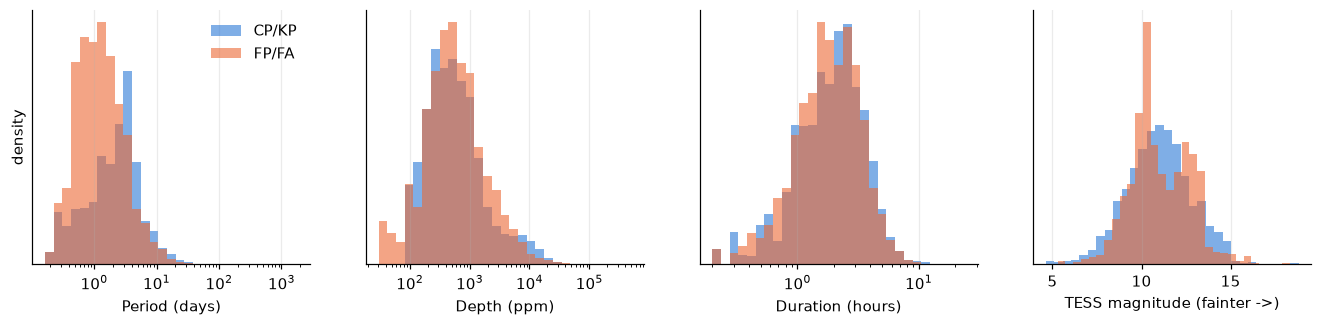

In [3]:
feats = [("period_days", "Period (days)", True), ("depth_ppm", "Depth (ppm)", True),
         ("duration_hours", "Duration (hours)", True), ("tmag", "TESS magnitude (fainter ->)", False)]
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, (col, name, log) in zip(axes, feats):
    x = lab[col].dropna()
    bins = np.geomspace(x[x > 0].min(), x.max(), 30) if log else 30
    for label, color, tag in [(1, POS, "CP/KP"), (0, NEG, "FP/FA")]:
        ax.hist(lab.loc[lab.label == label, col].dropna(), bins=bins, alpha=0.6, color=color,
                label=tag, density=True)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(name); ax.set_yticks([])
axes[0].set_ylabel("density"); axes[0].legend(frameon=False)
plt.show()

## 3. Is any single catalog feature a shortcut?
ROC AUC of each feature used alone as a score (0.5 = no information; 1.0 or 0.0 = perfect).
Values far from 0.5 are not bugs, but they tell us how much a model could get without looking at
the light curve at all.

In [4]:
rows = []
for col in ["period_days", "depth_ppm", "duration_hours", "tmag"]:
    d = lab[[col, "label"]].dropna()
    rows.append((col, len(d), roc_auc_score(d.label, d[col])))
print("feature            n   AUC")
for c, n, a in rows:
    print(f"{c:<16}{n:>6}  {a:.3f}")
print()
print("missing values in labeled set:")
print(lab[["period_days", "depth_ppm", "duration_hours", "tmag"]].isna().mean().round(3))

feature            n   AUC
period_days       2801  0.637
depth_ppm         2801  0.562
duration_hours    2801  0.532
tmag              2801  0.493

missing values in labeled set:
period_days       0.0
depth_ppm         0.0
duration_hours    0.0
tmag              0.0
dtype: float64


## 4. Stars with multiple TOIs (why we split by TIC ID)

In [5]:
per_star = df.groupby("tic_id").size()
print("stars:", len(per_star), "| with >1 TOI:", int((per_star > 1).sum()))
lab_star = lab.groupby("tic_id").label.agg(["size", "nunique"])
print("labeled stars with >1 labeled TOI:", int((lab_star["size"] > 1).sum()))
print("...of which have BOTH classes:", int((lab_star["nunique"] > 1).sum()))

stars: 7737 | with >1 TOI: 233
labeled stars with >1 labeled TOI: 108
...of which have BOTH classes: 5
